# 01 - Raw data audit
Goal: understand the 9 tables, their keys and relationships **before** joining anything, and find the
data-quality issues that drive later decisions (how to aggregate, what is missing, what is inconsistent).

In [1]:
# Cell 1 - make the project package importable and define folders
import sys, os, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
import numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 80)
from olist_risk import config
config.ensure_dirs()
print("PROJECT_ROOT =", PROJECT_ROOT)
print("outputs ->", config.OUTPUT_DIR)

PROJECT_ROOT = /workspace/ml_project2_v2
outputs -> /workspace/ml_project2_v2/outputs


In [2]:
# Cell 2 - load all raw tables (dates parsed, zip prefixes kept as 5-character strings)
from olist_risk import data
t = data.load_raw()
for k, v in t.items():
    print(f"{k:12s} {v.shape}")

orders       (99441, 8)
items        (112650, 7)
customers    (99441, 5)
sellers      (3095, 4)
products     (32951, 9)
payments     (103886, 5)
reviews      (99224, 7)
geolocation  (1000163, 5)
translation  (71, 2)


In [3]:
# Cell 3 - table-level audit: primary keys, duplicates, missing cells
tab = data.audit_tables(t)
tab.to_csv(config.TABLE_DIR / "01_table_audit.csv", index=False)
display(tab)

,table,rows,columns,primary_key,pk_unique,exact_duplicate_rows,cells_missing,columns_with_missing
0,orders,99441,8,order_id,True,0,4908,"order_approved_at=160, order_delivered_carrier_date=1783, order_delivered_cu..."
1,items,112650,7,order_id+order_item_id,True,0,0,
2,customers,99441,5,customer_id,True,0,0,
3,sellers,3095,4,seller_id,True,0,0,
4,products,32951,9,product_id,True,0,2448,"product_category_name=610, product_name_lenght=610, product_description_leng..."
5,payments,103886,5,order_id+payment_sequential,True,0,0,
6,reviews,99224,7,review_id+order_id,True,0,145903,"review_comment_title=87656, review_comment_message=58247"
7,geolocation,1000163,5,(none),None,261831,0,
8,translation,71,2,product_category_name,True,0,0,


In [4]:
# Cell 4 - relationships: which joins are 1:1 and which would multiply orders
rel = data.audit_relationships(t)
rel.to_csv(config.TABLE_DIR / "01_relationship_audit.csv", index=False)
display(rel)

,check,value
0,orders: unique order_id,True
1,orders: customer_id unique per order (1:1),True
2,orders without any item row,775
3,orders without any payment row,1
4,orders with >1 item row (join would multiply),9803
5,max item rows per order,21
6,orders with >1 seller,1278
7,orders with >1 payment row,2961
8,orders with >1 review row,547
9,geolocation rows per zip prefix (median),29.0


In [5]:
# Cell 5 - order lifecycle timestamps: missing values and inconsistencies
dates = data.audit_order_dates(t["orders"])
dates.to_csv(config.TABLE_DIR / "01_order_date_audit.csv", index=False)
display(dates)

,check,value
0,approved_at missing,160
1,approved before purchase,0
2,delivered_customer missing,2965
3,status=delivered but delivered_customer missing,8
4,status!=delivered but delivered_customer present,6
5,delivered to customer before carrier pickup,23
6,carrier pickup before approval,1359
7,delivered to customer before approval,61
8,estimated delivery has a time-of-day (non-midnight),0
9,purchase range,2016-09-04 21:15:19 .. 2018-10-17 17:30:18


In [6]:
# Cell 6 - order status distribution (final status at data export - an OUTCOME, never a feature)
st = t["orders"].order_status.value_counts().rename_axis("order_status").reset_index(name="orders")
st["share_%"] = (100 * st.orders / st.orders.sum()).round(2)
st["has_customer_delivery_date"] = st.order_status.map(
    t["orders"].groupby("order_status").order_delivered_customer_date.apply(lambda s: int(s.notna().sum())))
st.to_csv(config.TABLE_DIR / "01_order_status.csv", index=False)
display(st)

,order_status,orders,share_%,has_customer_delivery_date
0,delivered,96478,97.02,96470
1,shipped,1107,1.11,0
2,canceled,625,0.63,6
3,unavailable,609,0.61,0
4,invoiced,314,0.32,0
5,processing,301,0.30,0
6,created,5,0.01,0
7,approved,2,0.00,0


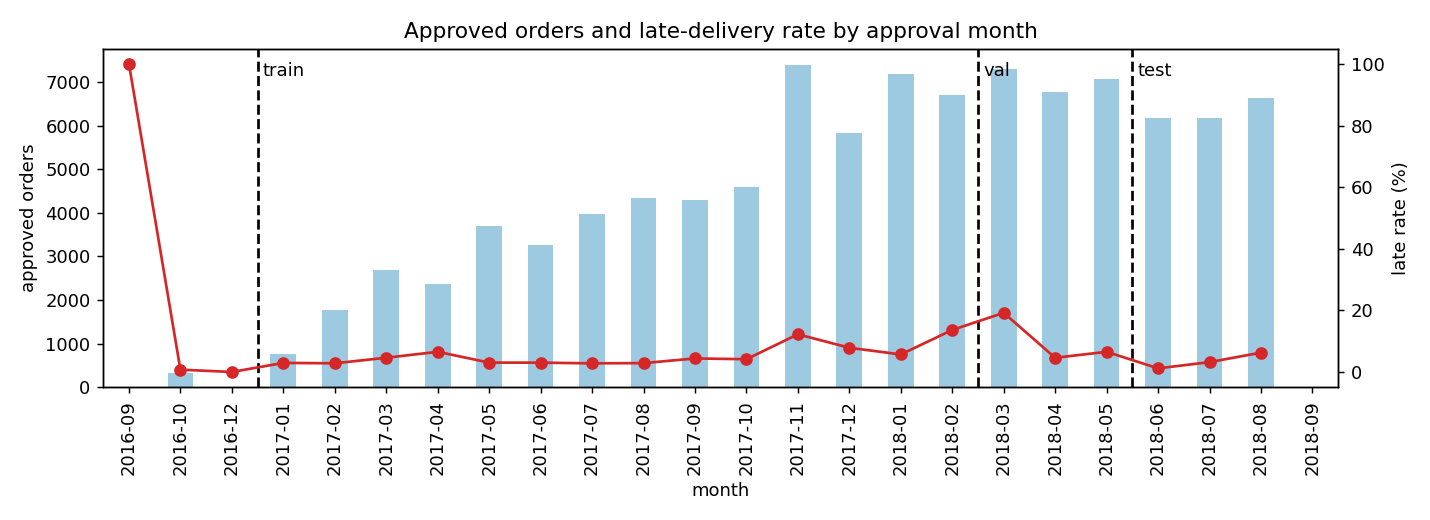

month,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,2017-08,2017-09,2017-10,2017-11,2017-12,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09
approved_orders,1.0,320.00,1.0,760.00,1765.00,2689.00,2374.00,3693.00,3252.00,3974.0,4348.00,4301.00,4590.00,7395.00,5832.00,7187.00,6706.00,7288.0,6778.00,7066.00,6164.00,6176.00,6620.00,1.0
delivered,1.0,270.00,1.0,715.00,1638.00,2554.00,2278.00,3547.00,3143.00,3828.0,4217.00,4170.00,4441.00,7149.00,5675.00,6991.00,6537.00,7083.0,6639.00,6940.00,6094.00,6047.00,6504.00,NaN
late_rate_%,100.0,0.74,0.0,2.94,2.81,4.62,6.54,3.04,3.02,2.8,2.87,4.39,4.14,12.23,7.86,5.68,13.63,19.2,4.61,6.54,1.17,3.19,6.27,NaN


In [7]:
# Cell 7 - monthly volume of approved orders and the share delivered late (preview of the target)
o = t["orders"].copy()
o["month"] = o.order_approved_at.dt.to_period("M")
dl = o[o.order_delivered_customer_date.notna()]
late = dl.order_delivered_customer_date.dt.normalize() > dl.order_estimated_delivery_date.dt.normalize()
monthly = pd.DataFrame({"approved_orders": o.groupby("month").size(),
                        "delivered": dl.groupby("month").size(),
                        "late_rate_%": (100 * late.groupby(dl.month).mean()).round(2)}).dropna(subset=["approved_orders"])
monthly.to_csv(config.TABLE_DIR / "01_monthly_volume_late_rate.csv")
fig, ax = plt.subplots(figsize=(11, 4))
monthly.approved_orders.plot(kind="bar", ax=ax, color="#9ecae1", label="approved orders")
ax2 = ax.twinx(); ax2.plot(range(len(monthly)), monthly["late_rate_%"], color="#d62728", marker="o", label="late rate %")
ax.set_ylabel("approved orders"); ax2.set_ylabel("late rate (%)"); ax.set_title("Approved orders and late-delivery rate by approval month")
for lbl, x0 in [("train", "2017-01"), ("val", "2018-03"), ("test", "2018-06")]:
    if pd.Period(x0) in monthly.index:
        i = list(monthly.index).index(pd.Period(x0)); ax.axvline(i - 0.5, color="k", ls="--"); ax.text(i - 0.4, ax.get_ylim()[1] * 0.92, lbl)
fig.tight_layout(); fig.savefig(config.FIG_DIR / "01_monthly_volume_late_rate.png", dpi=130); plt.close(fig)
display(Image(str(config.FIG_DIR / "01_monthly_volume_late_rate.png")))
display(monthly.T)

In [8]:
# Cell 8 - basket structure: items, sellers and payments per order (why we aggregate before joining)
it = t["items"]; p = t["payments"]
basket = pd.DataFrame({
    "items_per_order": it.groupby("order_id").size().describe(),
    "sellers_per_order": it.groupby("order_id").seller_id.nunique().describe(),
    "payment_rows_per_order": p.groupby("order_id").size().describe()}).round(3)
display(basket)
naive = t["orders"].merge(it, on="order_id").merge(p, on="order_id")
print(f"Naive orders x items x payments join: {len(naive):,} rows for {naive.order_id.nunique():,} orders "
      f"-> {len(naive) - naive.order_id.nunique():,} duplicated order rows. We aggregate each table per order first.")

,items_per_order,sellers_per_order,payment_rows_per_order
count,98666.000,98666.000,99440.000
mean,1.142,1.014,1.045
std,0.538,0.122,0.381
min,1.000,1.000,1.000
25%,1.000,1.000,1.000
50%,1.000,1.000,1.000
75%,1.000,1.000,1.000
max,21.000,5.000,29.000


Naive orders x items x payments join: 117,601 rows for 98,665 orders -> 18,936 duplicated order rows. We aggregate each table per order first.


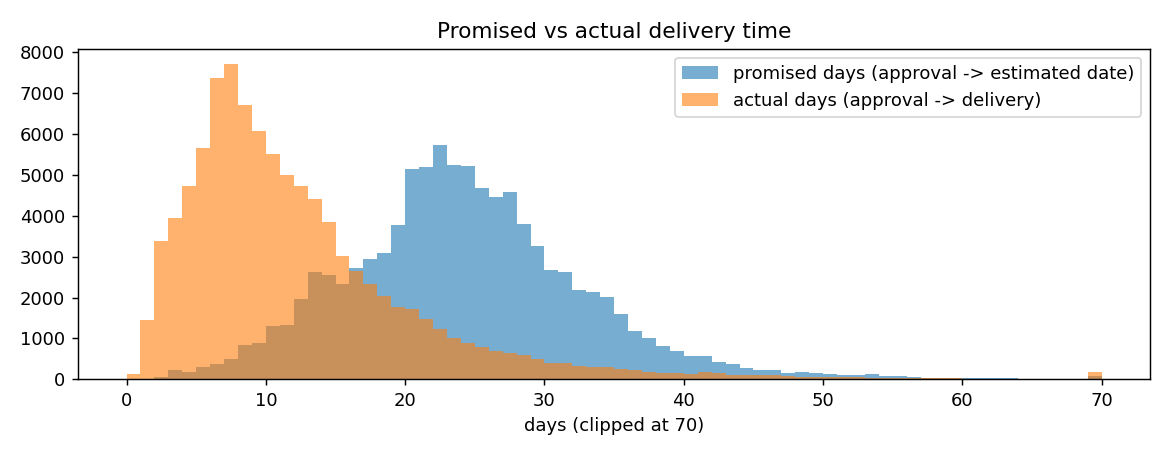

                 count  mean  std  min   25%   50%   75%    max
promised_days  96462.0  23.9  8.8 -6.0  18.0  23.0  29.0  154.0
actual_days    96462.0  12.0  9.5 -7.0   6.0  10.0  15.0  208.0


In [9]:
# Cell 9 - promised delivery window and actual delivery time (days) for delivered orders
dl = t["orders"].dropna(subset=["order_delivered_customer_date", "order_approved_at"])
promised = (dl.order_estimated_delivery_date - dl.order_approved_at.dt.normalize()).dt.days
actual = (dl.order_delivered_customer_date.dt.normalize() - dl.order_approved_at.dt.normalize()).dt.days
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(promised.clip(0, 70), bins=70, alpha=.6, label="promised days (approval -> estimated date)")
ax.hist(actual.clip(0, 70), bins=70, alpha=.6, label="actual days (approval -> delivery)")
ax.legend(); ax.set_xlabel("days (clipped at 70)"); ax.set_title("Promised vs actual delivery time")
fig.tight_layout(); fig.savefig(config.FIG_DIR / "01_promised_vs_actual_days.png", dpi=130); plt.close(fig)
display(Image(str(config.FIG_DIR / "01_promised_vs_actual_days.png")))
print(pd.DataFrame({"promised_days": promised.describe(), "actual_days": actual.describe()}).round(1).T)

In [10]:
# Cell 10 - reviews are written after delivery: proof that they cannot be approval-time features
rv = t["reviews"].merge(t["orders"][["order_id", "order_approved_at", "order_delivered_customer_date"]], on="order_id")
print("reviews created BEFORE approval :", int((rv.review_creation_date < rv.order_approved_at).sum()))
print("reviews created AFTER approval  :", int((rv.review_creation_date >= rv.order_approved_at).sum()))
print("median days review created after delivery:",
      (rv.review_creation_date - rv.order_delivered_customer_date).dt.days.median())
print("-> the reviews table is never joined into the feature table.")

reviews created BEFORE approval : 33
reviews created AFTER approval  : 99035
median days review created after delivery: 0.0
-> the reviews table is never joined into the feature table.
